Queremos encontrar $\pi \in \text{Adm}(Q,q):=\bigl\{ \pi \in \mathbb{H}_{\ge}(\mathcal{H}) \ : \ \operatorname{Tr}[Q_i \pi] = q_i, \ 0 \le i \le M \bigr\}$ que minimiza a seguinte expressão:

$$ \mathcal{F}_\epsilon(\pi) = Tr[H\pi]+ \epsilon Tr[\pi(log \pi -1)]$$

Podemos encontrar a forma de $\pi$ como solução para  $\mathcal{F}_\epsilon$:

$$\pi^* = \text{exp}(\frac{1}{\epsilon}(\sum_{i=0}^M u_iQ_i - H))$$

Dessa forma, o "dual" do nosso problema regularizado assume a seguinte forma:

$$
\min_{u \in \mathbb{R}^{M+1}} \left\{ \epsilon \operatorname{Tr}\left[ \exp\left( \frac{\sum_{i=0}^M u_i Q_i - H}{\epsilon} \right) \right] - \sum_{i=0}^M u_i q_i \right\}
$$

## Lista do que foi desenvolvido até o presente commit

- Implementação da reconstrução de um estado com a regularização entrópica via: 
    *  Gradient Descent:
        * Teste básico de reconstrução usando medidas incompletas
        * Teste com os dados da implementação anterior comparando iterações vs. epsilon/learning rate
        * Teste usando medidas completas com um estado puro (análise da convergência do gradiente)
        * Comparação entre convergência de estado puro com estado com medidas incompletas

    * Stochastic Method:
        * Teste básico de reconstrução usando medidas incompletas
        * Teste com os dados da implementação anterior comparando iterações vs. epsilon/learning rate
    
    * Both:
        * Comparando convergência do gradiente com a reconstrução a partir de medidas incompletas (mesmos dados)

## Lista daquilo que ainda falta fazer
* Verificar  em ambos métodos a convergência/tempo do algoritmo para números maiores de qubits e fazer as comparações/variações necessárias para alguma análise (Realizar a tomografia completa até onde der e verificar a escalabilidade)
* 

# Plano de trabalho: tomografia com regularização entrópica

## Fase 0: infraestrutura

- [V] Gerador de estados verdadeiros: puros (produto, GHZ, W, Haar), mistos (Werner, GHZ despolarizado, Ginibre) e Gibbs de Ising/Heisenberg com $\beta$ variável
- [ ] Gerador de conjuntos $Q$: (a) Pauli completo, (b) subconjunto aleatório de fração $f$, (c) termos locais (1 e 2 corpos)
- [ ] Função de métricas: $\|\nabla\|$, fidelidade, distância de traço, $S(\rho)$, pureza, $\lambda_{\min}$
- [ ] Rotina que roda um experimento e salva em `.npz` (parâmetros, trajetória do gradiente, $u$ final, tempo, sementes); gráficos em scripts separados
- [ ] Soluções de referência: fórmula fechada para dados completos e L-BFGS do scipy para o caso geral

## Fase 1: validação ($n = 1$ a $3$)

- [ ] Dados completos de um estado misto: $\pi^*$ coincide com $\rho$ e $u$ com a fórmula fechada
- [ ] Gibbs com $Q = \{I\}$: $\pi^* = e^{-H/\epsilon}/Z$
- [ ] Gibbs com os termos de $H$ medidos e $H = 0$: recupera o estado exatamente
- [ ] GD, SGD e L-BFGS dão o mesmo $\pi^*$ nos casos acima

**Resultado:** tabela ou figura mostrando que as implementações estão corretas.

## Fase 2: convergência por tipo de estado ($n = 3$ ou $4$)

- [ ] Rodar GD e SGD para todas as famílias da Fase 0, com 20–50 sementes nos estados aleatórios
- [ ] Fixar $lr = c\cdot\epsilon$ para comparações justas

Gráficos:

- [ ] $\|\nabla\|$ × iteração (semilog), uma curva por família, com faixa sombreada
- [ ] **Iterações até a tolerância × $S(\rho)$**, dispersão única com todas as famílias
- [ ] Iterações × $\beta$ no Gibbs (transição de fácil para difícil)
- [ ] Estados puros: $\|u\|$ × iteração (deve crescer) e convergência sublinear
- [ ] $lr$ máximo estável × $\epsilon$
- [ ] Dados incompletos: erro até $\rho_{\text{verdadeiro}}$ × fração $f$ de Paulis, com e sem $H$, para vários $\epsilon$

**Mensagem:** a dureza é controlada pelo espectro de $\rho$, e a regularização escolhe o completamento de máxima entropia nos casos incompletos.

## Fase 3: escalabilidade

- [ ] **Regime A (Pauli completo):** $n = 1, 2, 3, \dots$ até o tempo ou a memória estourarem
- [ ] **Regime B (Gibbs local, observáveis locais, $H = 0$):** $n$ maior, até cerca de 10–12
- [ ] Comparar GD e SGD com vários $k$, usando tolerância fixa

Gráficos:

- [ ] Tempo por iteração × $n$ (semilog), com ajuste exponencial
- [ ] Iterações até a tolerância × $n$
- [ ] Custo total × $n$
- [ ] Memória × $n$
- [ ] GD × SGD em avaliações de $\text{Tr}[Q_i\pi]$ consumidas e em tempo de relógio (hipótese: o SGD só compensa quando $k \ll m$ com $m$ grande, ponto de virada em $k \approx d$)

**Mensagem:** onde está o muro computacional, o que o causa (exponencial $d\times d$ e memória) e se o SGD o desloca.

## Fase 4: Weyl e Wigner

**Contínuo (Fock truncado, $N \approx 40$–$60$):**

- [ ] $Q = \{1, x, p, x^2+p^2\}$, $H = 0$, momentos de um estado gaussiano: $\pi^*$ deve ser o gaussiano
- [ ] $Q = \{1\}$, $H = a^\dagger a$: $\pi^*$ deve ser o térmico com $T = \epsilon$
- [ ] Estado gato com poucos observáveis: ver a perda de franjas e de negatividade
- [ ] Observáveis de Weyl hermitianos, $(D+D^\dagger)/2$ e $(D-D^\dagger)/2i$, em pontos $\alpha$ de uma grade

**Discreto (qubits):**

- [ ] Mapa $2^n \times 2^n$ dos valores de $\text{Tr}[P\rho]$ (verdadeiro × $\pi^*$ × diferença) para vários $f$
- [ ] Transformada para a Wigner discreta

Figuras: Wigner verdadeira, Wigner de $\pi^*$, diferença, e variação com o número de pontos de Weyl medidos.

**Mensagem:** os dados fixam parte da função característica, e a entropia completa o resto da forma mais suave possível.

## Fase 5: apresentação

1. Problema e dual
2. Validação (Fase 1)
3. Convergência × estado (Fase 2)
4. Escalabilidade (Fase 3)
5. Weyl e Wigner (Fase 4)
6. Conclusões e limitações (estados puros, dados com ruído)

## A combinar com o professor

- [ ] Papel de $H$ na tomografia
- [ ] Dados com ruído (shots) ou só dados exatos
- [ ] Wigner discreta ou contínua
- [ ] QuTiP ou QuTIpy

In [26]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.optimize import least_squares


# Importa as bibliotecas desenvolvida para o projeto
import quantum_tomography as qt
import entropyreg as er

In [27]:
# Teste básico Gradient Descent
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

pistar_data = er.reconstruct_pi(H, Q, q, epsilon, lr=0.5, max_iters=10000, tol=1e-6)
pistar = pistar_data[0]
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Matriz reconstruída pi*:")
print(pistar)

(1.000000678201519+4.4185586538597856e-17j) (0.6999994111561818-2.7755575615628914e-17j) (0.3999996635178181+5.551115123125783e-17j)
Matriz reconstruída pi*:
[[0.50000034+3.68423441e-17j 0.34999971-1.99999832e-01j]
 [0.34999971+1.99999832e-01j 0.50000034+7.34324243e-18j]]


In [28]:
# Teste básico Stochastic Method
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

stocpistar_data = er.reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=1, tol=1e-6, k=2, count_it=1)
stocpistar, stoc_u_opt, stoc_n_it, stoc_pi_grad  = stocpistar_data
stoc_grad_data = np.array(stoc_pi_grad)

print("iterações:", stoc_n_it)
print(np.trace(stocpistar), np.trace(stocpistar @ Q[1]), np.trace(stocpistar @ Q[2]))
print("Matriz reconstruída pi*:")
print(stocpistar)

iterações: 100
(1.0000000001282152-1.0194436133805656e-17j) (0.6999999783829212-5.551115123125783e-17j) (0.3999999874537122+5.551115123125783e-17j)
Matriz reconstruída pi*:
[[0.5       +2.53539514e-17j 0.34999999-1.99999994e-01j]
 [0.34999999+1.99999994e-01j 0.5       -3.55483875e-17j]]


In [29]:
# Teste variando epsilon e learning rate Gradient Descent
epsilon_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

pieps = []
piepsit = []
pilr = []
pilrit = []

for epsilon in epsilon_values:
    result = er.reconstruct_pi(H, Q, q, epsilon, lr=0.01, max_iters=100000, tol=1e-6)
    pieps.append(result[0])
    piepsit.append(result[2])

for lr in lr_values:
    result = er.reconstruct_pi(H, Q, q, epsilon=1.0, lr=lr, max_iters=100000, tol=1e-6)
    pilr.append(result[0])
    pilrit.append(result[2])

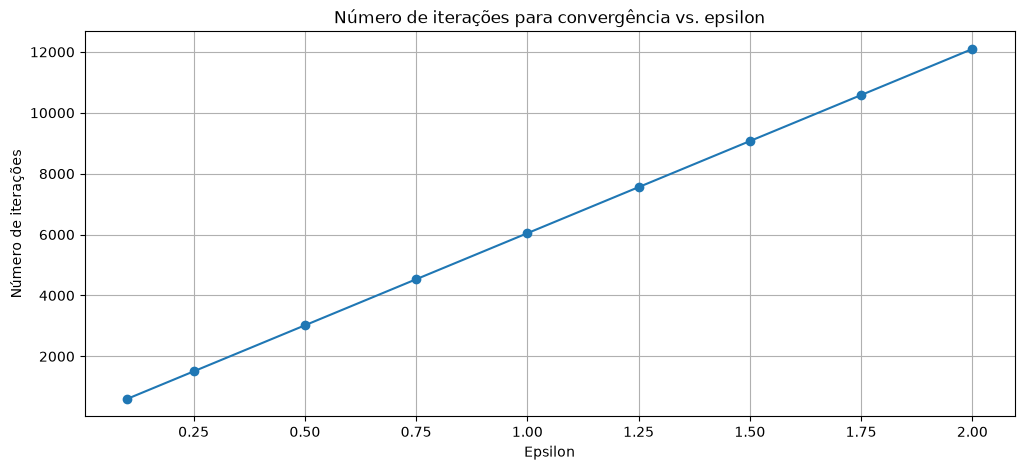

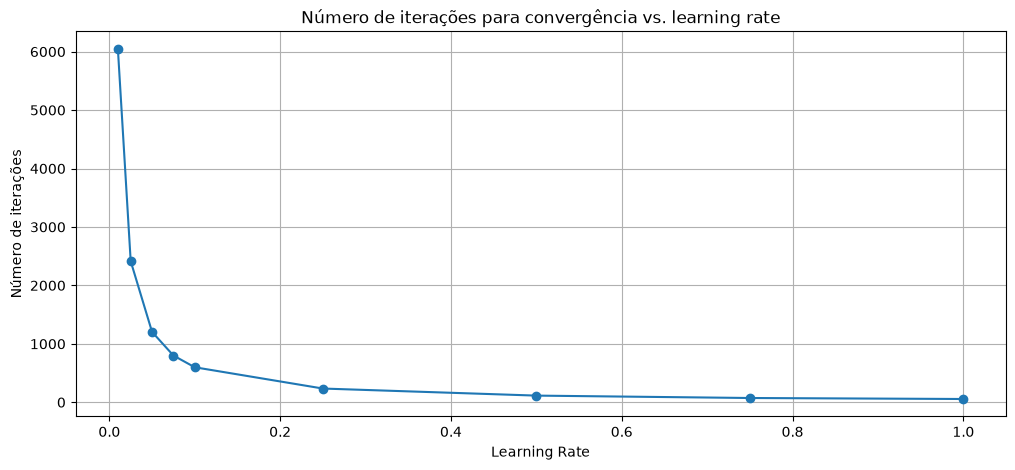

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(epsilon_values, piepsit, marker='o')
plt.title("Número de iterações para convergência vs. epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Número de iterações")
plt.grid()

plt.figure(figsize=(12, 5))
plt.plot(lr_values, pilrit, marker='o')
plt.title("Número de iterações para convergência vs. learning rate")
plt.xlabel("Learning Rate")
plt.ylabel("Número de iterações")
plt.grid()

In [31]:
# Teste variando epsilon e learning rate Stochastic Method
eps_values = [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_val = [0.01, 0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75, 1.0]

pieps, piepsit = [], []
pilr, pilrit = [], []

for epsilon in eps_values:
    result = er.reconstruct_spi(H, Q, q, epsilon, lr=0.01, max_iters=100000, tol=1e-6, k=2)
    pieps.append(result[0])
    piepsit.append(result[2])

for lr in lr_val:
    result = er.reconstruct_spi(H, Q, q, epsilon=1.0, lr=lr, max_iters=100000, tol=1e-6, k=2)
    pilr.append(result[0])
    pilrit.append(result[2])

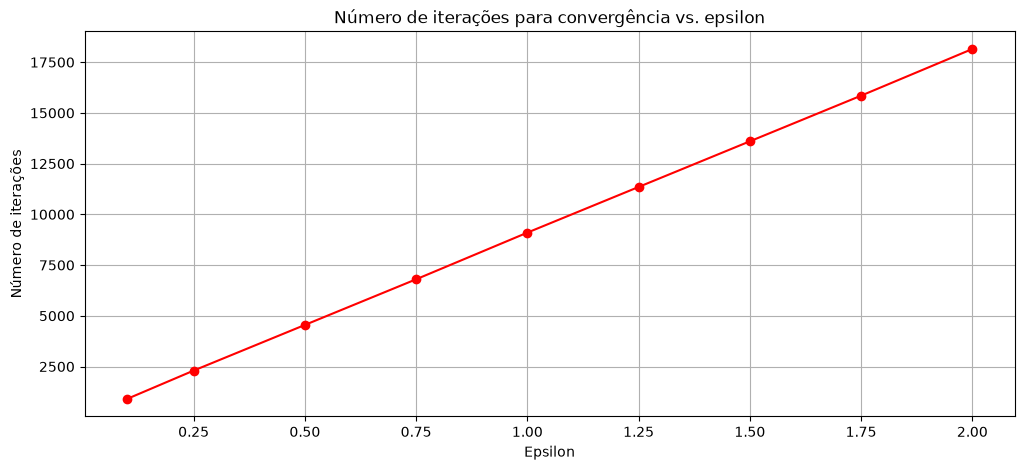

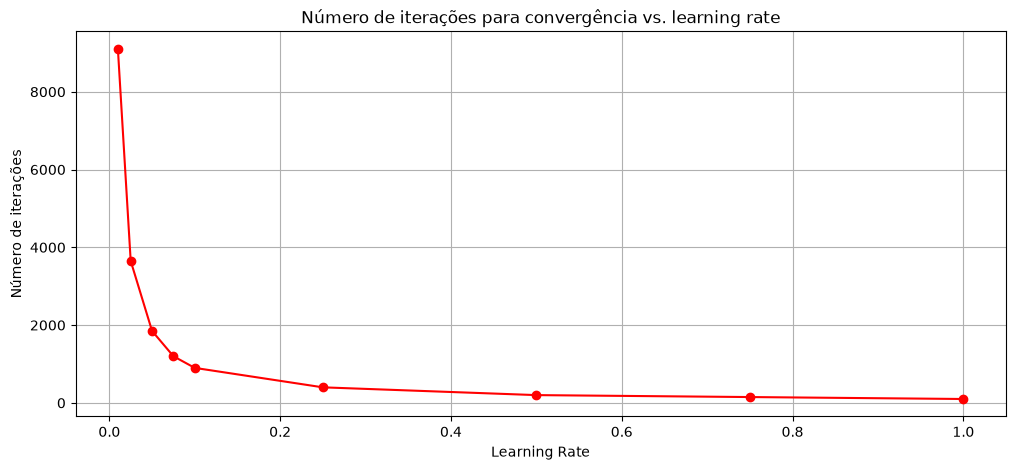

In [32]:
plt.figure(figsize=(12, 5))
plt.plot(eps_values, piepsit, marker='o', color = 'red')
plt.title("Número de iterações para convergência vs. epsilon")
plt.xlabel("Epsilon")
plt.ylabel("Número de iterações")
plt.grid()

plt.figure(figsize=(12, 5))
plt.plot(lr_val, pilrit, marker='o', color='red')
plt.title("Número de iterações para convergência vs. learning rate")
plt.xlabel("Learning Rate")
plt.ylabel("Número de iterações")
plt.grid()

In [42]:
# Comparação de convergência estado puro e não único Gradient Descent 
"""
Definimos um estado conhecido e utilizamos-no 
para determinar as medidas q. Em seguida, usamos
o gradient descento com a regularização entrópica
para reconstruir o estado. Faremos isso para 
conseguirmoss verificar a convergência do método 
a partir de um gráfico que mostra o módulo do gradiente
do problema em função do número de iterações.
"""

unk_state = qt.QuantState([2.0 / np.sqrt(5.0), 1.0 / np.sqrt(5.0)])
obs = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y"), qt.pauli_string_to_matrix("Z")]
qs = qt.measure_observables(unk_state, obs)

# Estado puro
conv_data = er.reconstruct_pi(H, obs, qs, epsilon, lr=2, max_iters=1000000, tol=1e-6)[4]

# Estado não único
conv_data2 = pistar_data[4]


data = np.array(conv_data)
data2 = np.array(conv_data2)

its, gnorms = data[:, 0], data[:, 1]
its2, gnorms2 = data2[:, 0], data2[:, 1]



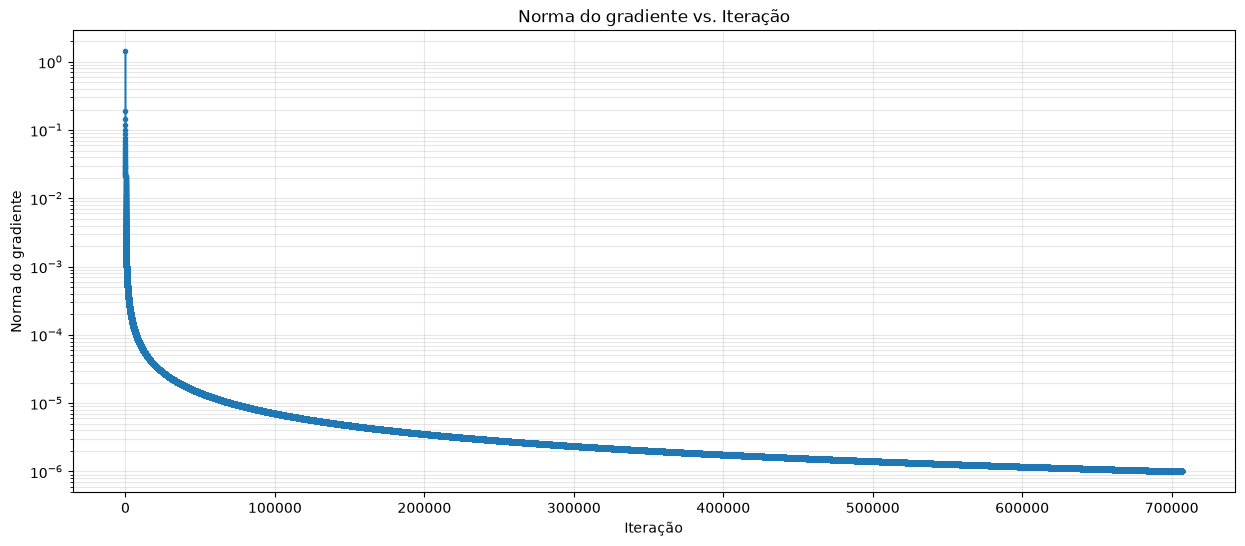

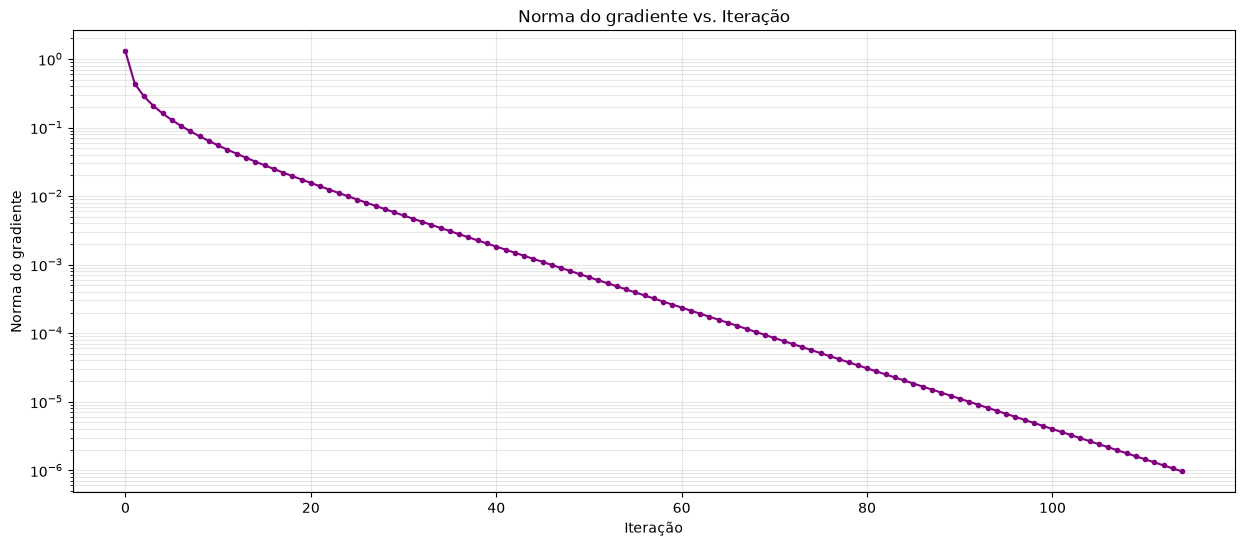

In [34]:
plt.figure(figsize=(15, 6))
plt.semilogy(its, gnorms, marker='o', markersize=3)
plt.title("Norma do gradiente vs. Iteração")
plt.xlabel("Iteração")
plt.ylabel("Norma do gradiente")
plt.grid(True, which="both", alpha=0.3)
plt.show()

plt.figure(figsize=(15, 6))
plt.semilogy(its2, gnorms2, marker='o', markersize=3, color='purple')
plt.title("Norma do gradiente vs. Iteração")
plt.xlabel("Iteração")
plt.ylabel("Norma do gradiente")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [38]:
# Comparação de convergência estado puro e não único Stochastic Method 

# Estado puro
conv_data = er.reconstruct_spi(H, obs, qs, epsilon, lr=2, max_iters=1000000, tol=1e-6, count_it=1)[3]

# Estado não único
conv_data2 = stocpistar_data[3]


data = np.array(conv_data)
data2 = np.array(conv_data2)

stoc_its, stoc_gnorms = data[:, 0], data[:, 1]
stoc_its2, stoc_gnorms2 = data2[:, 0], data2[:, 1]



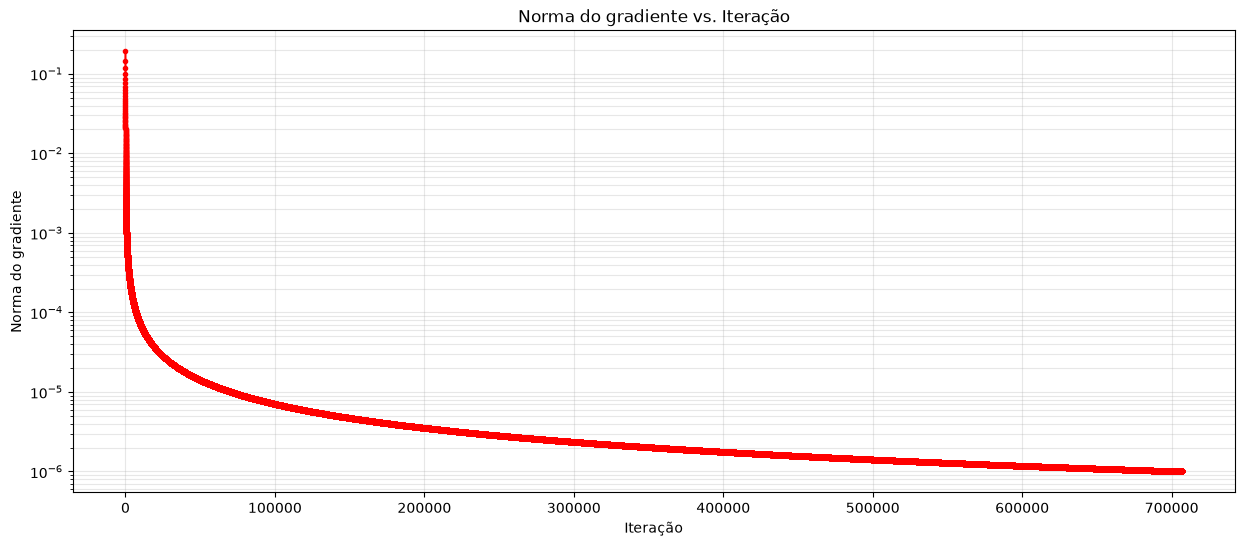

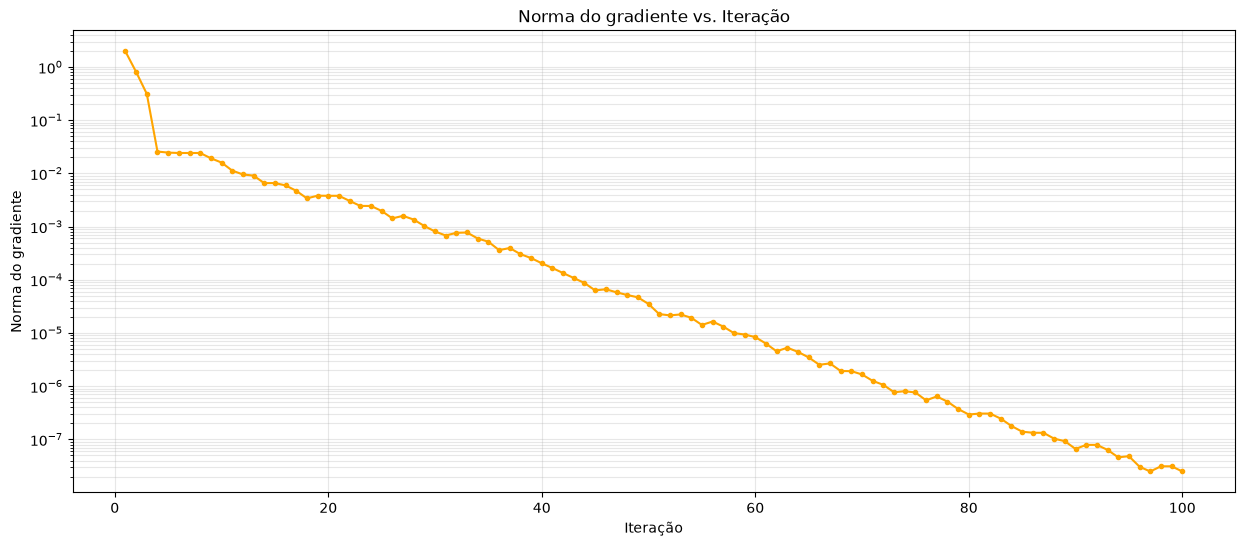

In [39]:
plt.figure(figsize=(15, 6))
plt.semilogy(stoc_its, stoc_gnorms, marker='o', markersize=3, color='red')
plt.title("Norma do gradiente vs. Iteração")
plt.xlabel("Iteração")
plt.ylabel("Norma do gradiente")
plt.grid(True, which="both", alpha=0.3)
plt.show()

plt.figure(figsize=(15, 6))
plt.semilogy(stoc_its2, stoc_gnorms2, marker='o', markersize=3, color='orange')
plt.title("Norma do gradiente vs. Iteração")
plt.xlabel("Iteração")
plt.ylabel("Norma do gradiente")
plt.grid(True, which="both", alpha=0.3)
plt.show()

## Comparações entre Stochastic Method e Gradient Descent

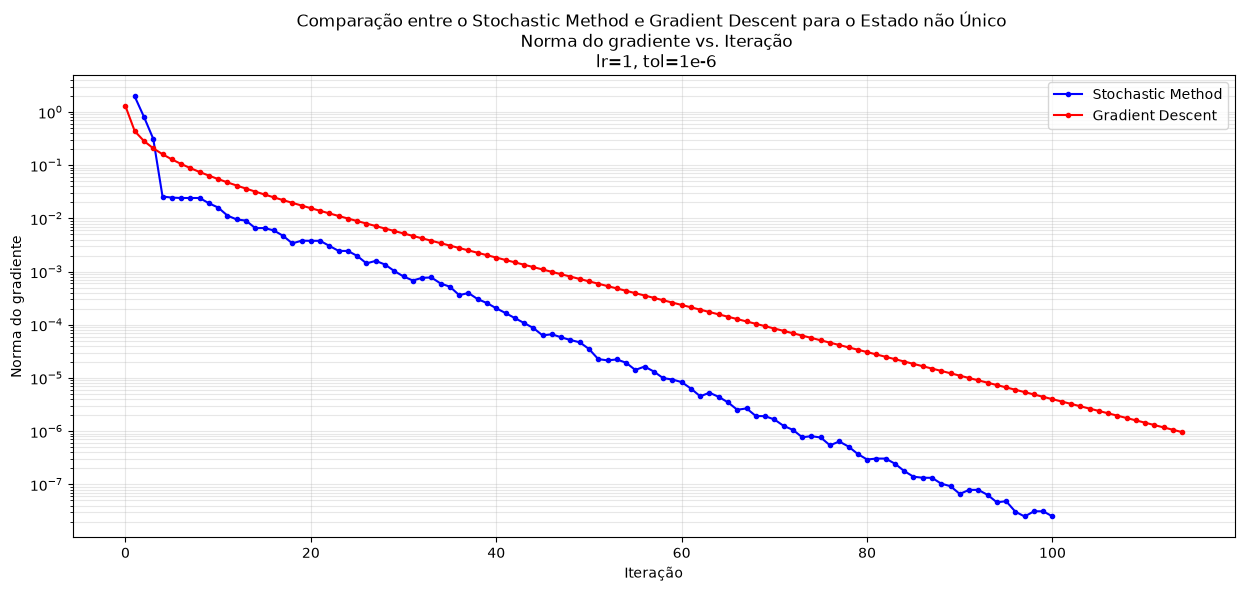

In [44]:
# Comparação entre o Stochastic Method e Gradient Descent usando o estado não único

plt.figure(figsize=(15, 6))
plt.semilogy(stoc_its, stoc_gnorms, marker='o', markersize=3, color='blue')
plt.semilogy(its2, gnorms2, marker='o', markersize=3, color='red')
plt.title("Comparação entre o Stochastic Method e Gradient Descent para o Estado não Único \n Norma do gradiente vs. Iteração" \
"\n lr=1, tol=1e-6")
plt.legend(["Stochastic Method", "Gradient Descent"])
plt.xlabel("Iteração")
plt.ylabel("Norma do gradiente")
plt.grid(True, which="both", alpha=0.3)
plt.show()



## Aumentando o Número de Qubits